In [44]:
# --- Setup ---
import os
import torch
import torch.nn as nn
import torch.optim as optim
import joblib
import numpy as np
from tqdm import tqdm
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

In [54]:
# --- Constants ---
PKL_DIR = "/x1/ljiao/Bhanu/VIBE/cAvatar/dance"
FRAMES_ROOT = "/x1/ljiao/Bhanu/VIBE/output/dance"
J_REGRESSOR_PATH = "/x1/ljiao/Bhanu/VIBE/data/J_regressor_h36m.npy"  # Path to SMPL joint regressor matrix (should be 49 x 6890)
BATCH_SIZE = 32
EPOCHS = 20

In [46]:
# --- Dataset Loader ---
class PoseMeshDataset(Dataset):
    def __init__(self, pkl_dir, frames_root):
        self.data = []
        pkl_files = [f for f in os.listdir(pkl_dir) if f.endswith('.pkl')]
        for file_name in tqdm(pkl_files, desc="🧠 Building dataset"):
            pkl_path = os.path.join(pkl_dir, file_name)
            base_name = file_name.replace('.pkl', '')
            frame_folder = os.path.join(frames_root, base_name + '_frames')
            if not os.path.isdir(frame_folder):
                continue
            try:
                data = joblib.load(pkl_path)[1]  # Assuming single human
                frame_ids = data['frame_ids']
                for idx, frame_id in enumerate(frame_ids):
                    self.data.append({
                        'joints2d': data['joints2d'][idx],
                        'verts': data['verts'][idx],
                        'joints3d': data['joints3d'][idx]  # optional for GT comparison
                    })
            except Exception as e:
                print(f"Error loading {file_name}: {e}")

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        sample = self.data[idx]
        joints2d = torch.tensor(sample['joints2d'], dtype=torch.float32).flatten()  # shape (98,)
        verts = torch.tensor(sample['verts'], dtype=torch.float32).flatten()        # shape (20670,)
        joints3d = torch.tensor(sample['joints3d'], dtype=torch.float32)            # shape (49, 3)
        return joints2d, verts, joints3d

In [47]:
# --- Simple MLP Model ---
class Pose2MeshMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(98, 512),
            nn.ReLU(),
            nn.Linear(512, 1024),
            nn.ReLU(),
            nn.Linear(1024, 20670)  # 6890 * 3
        )

    def forward(self, x):
        return self.model(x)

In [48]:
# --- Training ---
def train_model(model, dataloader, device, num_epochs=20):
    model.train()
    model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-4)
    loss_fn = nn.MSELoss()

    for epoch in range(num_epochs):
        total_loss = 0
        for inputs, targets, _ in tqdm(dataloader, desc=f"Epoch {epoch+1}/{num_epochs}"):
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = loss_fn(outputs, targets)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"✅ Epoch {epoch+1} Loss: {total_loss/len(dataloader):.6f}")

In [56]:
# --- Evaluation: MPJPE with J_regressor (H36M-compatible) ---
def evaluate_mpjpe_with_regressor(model, dataloader, device, j_regressor):
    model.eval()
    total_error = 0
    total_joints = 0
    j_regressor = torch.tensor(j_regressor, dtype=torch.float32).to(device)  # (17, 6890)

    with torch.no_grad():
        for inputs, _, gt_joints3d in tqdm(dataloader, desc="🔍 Evaluating MPJPE w/ regressor"):
            inputs = inputs.to(device)
            predicted_verts = model(inputs).reshape(-1, 6890, 3)  # (B, 6890, 3)

            # Predict 3D joints from predicted mesh using regressor
            pred_joints3d = torch.matmul(j_regressor, predicted_verts)  # (B, 17, 3)

            # Align ground-truth joints to same shape (only first 17 joints)
            gt_joints3d = gt_joints3d[:, :17, :].to(device)  # (B, 17, 3)

            # Compute MPJPE
            error = torch.norm(pred_joints3d - gt_joints3d, dim=-1).mean()
            total_error += error.item() * inputs.size(0)
            total_joints += inputs.size(0)

    mpjpe = total_error / total_joints
    print(f"📏 MPJPE (H36M aligned, using regressor): {mpjpe:.4f} meters")


In [50]:
# --- Execution ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dataset = PoseMeshDataset(PKL_DIR, FRAMES_ROOT)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

🧠 Building dataset:  17%|█▋        | 71/425 [00:00<00:01, 237.51it/s]

Error loading Small_short_skirt_of_rabbit_ears_COS_sister_curtilage_dance_3_jumpers_dance_26_clip1.pkl: 1


🧠 Building dataset:  48%|████▊     | 202/425 [00:00<00:00, 260.32it/s]

Error loading Ziqi_flip_jump_jump_gold_in_the_summer_please_return_to_Snapping_power_P2_vertical_screen_version_of_P1_golden_summer_Snapping_please_turn_to_jump_dance_7_clip1.pkl: 1


🧠 Building dataset: 100%|██████████| 425/425 [00:01<00:00, 257.69it/s]


In [51]:
model = Pose2MeshMLP()
train_model(model, dataloader, device, num_epochs=EPOCHS)

Epoch 1/20: 100%|██████████| 3276/3276 [00:10<00:00, 303.44it/s]


✅ Epoch 1 Loss: 0.003580


Epoch 2/20: 100%|██████████| 3276/3276 [00:10<00:00, 303.11it/s]


✅ Epoch 2 Loss: 0.001163


Epoch 3/20: 100%|██████████| 3276/3276 [00:10<00:00, 302.69it/s]


...

✅ Epoch 18 Loss: 0.000280


Epoch 19/20: 100%|██████████| 3276/3276 [00:10<00:00, 302.14it/s]


✅ Epoch 19 Loss: 0.000271


Epoch 20/20: 100%|██████████| 3276/3276 [00:10<00:00, 303.54it/s]

✅ Epoch 20 Loss: 0.000263


In [57]:
# Load J_regressor (should be shape: 49 x 6890)
j_regressor = np.load(J_REGRESSOR_PATH)
evaluate_mpjpe_with_regressor(model, dataloader, device, j_regressor)

🔍 Evaluating MPJPE w/ regressor: 100%|██████████| 3276/3276 [00:08<00:00, 383.24it/s]

📏 MPJPE (H36M aligned, using regressor): 0.7737 meters


In [71]:
# --- Save Model ---
torch.save(model.state_dict(), "pose2mesh_model.pth")

In [64]:
# --- Visualization: Mesh + Joints (GT & Predicted) ---
def visualize_mesh_and_joints(model, dataset, device, j_regressor, index=0):
    model.eval()
    j_regressor = torch.tensor(j_regressor, dtype=torch.float32).to(device)
    joints2d, verts_gt, joints3d_gt = dataset[index]
    inputs = joints2d.unsqueeze(0).to(device)

    with torch.no_grad():
        verts_pred = model(inputs).reshape(-1, 6890, 3).cpu().squeeze(0)
        joints_pred = torch.matmul(j_regressor, verts_pred.to(device)).cpu().numpy()

    verts_gt = verts_gt.reshape(6890, 3).numpy()
    joints_gt = joints3d_gt[:17].numpy()

    fig = plt.figure(figsize=(12, 5))
    ax1 = fig.add_subplot(121, projection='3d')
    ax1.scatter(*verts_gt.T, s=0.5, c='green')
    ax1.scatter(*joints_gt.T, s=10, c='black')
    ax1.set_title('GT Mesh + Joints')

    ax2 = fig.add_subplot(122, projection='3d')
    ax2.scatter(*verts_pred.T, s=0.5, c='red')
    ax2.scatter(*joints_pred.T, s=10, c='black')
    ax2.set_title('Pred Mesh + Joints')

    for ax in (ax1, ax2):
        ax.set_xlabel("X")
        ax.set_ylabel("Y")
        ax.set_zlabel("Z")
        ax.view_init(elev=200, azim=270)
    plt.tight_layout()
    plt.show()

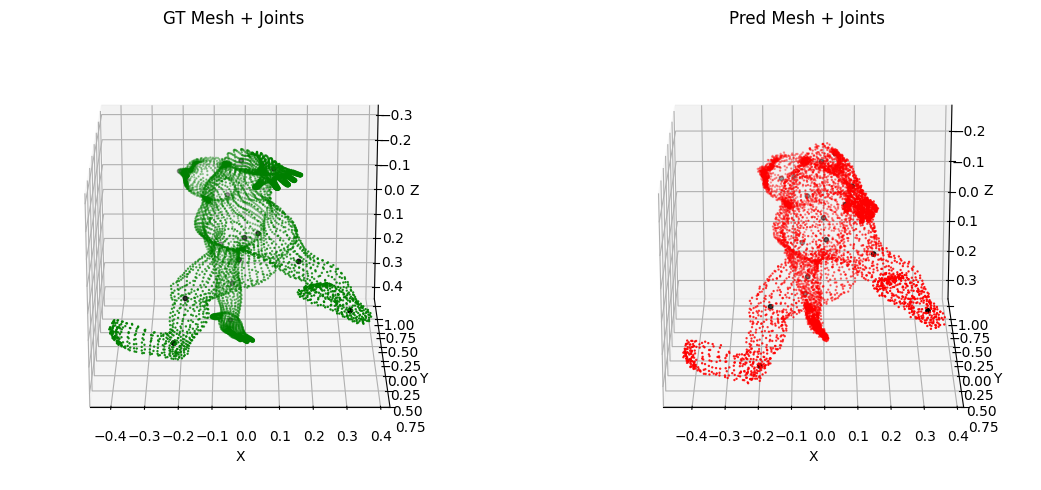

In [75]:
# Visualize mesh with joints
visualize_mesh_and_joints(model, dataset, device, j_regressor, index=88890)